In [1]:
from buoyscraper import Buoy

In [2]:
perouse_id = 46206
brooks_id = 46132
neah_id = 46087
middle_nomad_id = 46004

## La Perouse Bank Buoy

In [3]:
perouse = Buoy(perouse_id)
perouse.metadata

{'buoy_id': '46206',
 'owner': 'Environment and Climate Change Canada, CA',
 'ttype': '3-meter discus buoy',
 'hull': nan,
 'name': 'La Perouse Bank',
 'timezone': 'P',
 'forecast': ' ',
 'note': nan,
 'latitude': '48.840',
 'longitude': '-126.000'}

### Realtime Data

In [4]:
print(perouse.get_realtime_dtypes())

['stdmet']


In [5]:
help(perouse.realtime.stdmet)

Help on method stdmet in module buoyscraper.datascrapers.realtime_scraper:

stdmet(url) method of buoyscraper.datascrapers.realtime_scraper.RealtimeScraper instance
    Standard Meteorological Data
    dtype:   "stdmet"
    index:   datetime64[ns, UTC]
    columns: WDIR  WSPD  GST  WVHT  DPD  APD  MWD  PRES  ATMP  WTMP  DEWP  VIS  PTDY  TIDE
    units:   degT  m/s   m/s   m    sec  sec  degT  hPa  degC  degC  degC  nmi  hPa    ft



In [6]:
p_stdmet = perouse.get_realtime('stdmet').tz_convert('US/Pacific')
print(max(p_stdmet.index) - min(p_stdmet.index))
p_stdmet.head()

1 days 00:00:00


columns,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,PTDY,TIDE
datetime,,,,,,,,,,,,,,
2020-11-28 11:00:00-08:00,50,2.0,3.0,2.6,10,NaN,NaN,1028.4,8.1,9.8,NaN,NaN,1.8,NaN
2020-11-28 10:00:00-08:00,40,3.0,5.0,2.7,11,NaN,NaN,1028.0,8.1,9.8,NaN,NaN,2.0,NaN
2020-11-28 09:00:00-08:00,310,6.0,7.0,2.8,11,NaN,NaN,1027.4,8.9,9.8,NaN,NaN,2.0,NaN
2020-11-28 08:00:00-08:00,310,6.0,7.0,3.0,10,NaN,NaN,1026.6,8.7,9.8,NaN,NaN,1.6,NaN
2020-11-28 07:00:00-08:00,320,6.0,7.0,3.0,10,NaN,NaN,1026.0,8.6,9.8,NaN,NaN,1.7,NaN


### Wave Charts

In [13]:
import matplotlib.pyplot as plt
%matplotlib inline

def waves_chart(stdmet):
    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax2 = ax1.twinx()
    ax1.plot(stdmet['WVHT']*3.28084, 'b-', linewidth=1, label='WVHT')
    ax1.set_ylabel('height (feet)', color='b', size=16)
    ax1.legend(loc="upper left")
    ax2.plot(stdmet['DPD'], 'g-', linewidth=1, label='DPD')
    ax2.set_ylabel('period (sec)', color='g', size=16)
    ax2.legend()
    return fig

In [14]:
brooks = Buoy(brooks_id)
b_stdmet = brooks.get_realtime('stdmet').tz_convert('US/Pacific')

In [15]:
neah = Buoy(neah_id)
n_stdmet = neah.get_realtime('stdmet').tz_convert('US/Pacific')

In [16]:
middle_nomad = Buoy(middle_nomad_id)
m_stdmet = middle_nomad.get_realtime('stdmet').tz_convert('US/Pacific')

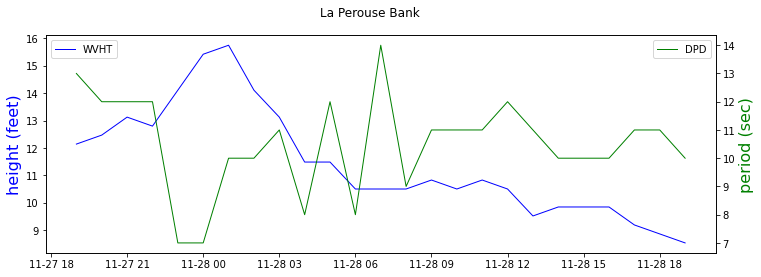

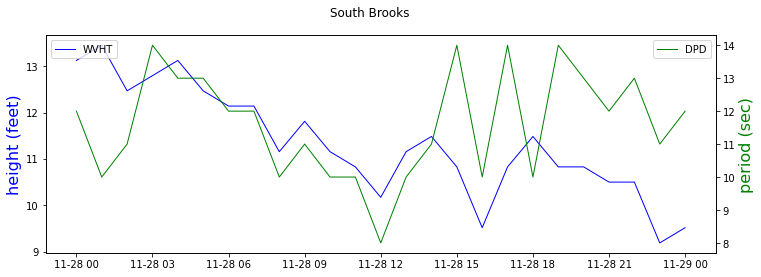

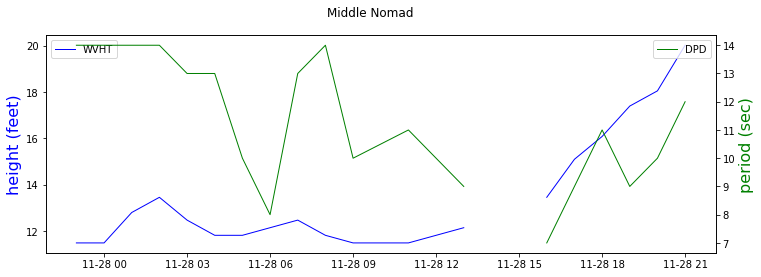

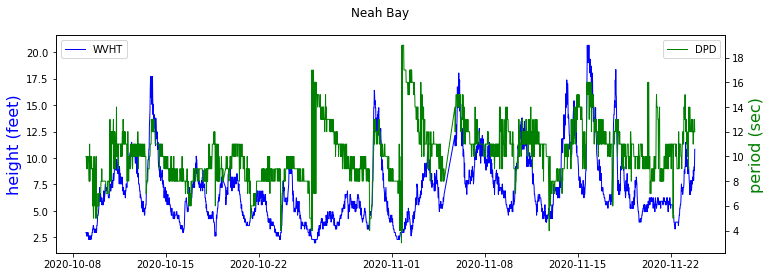

In [17]:
fig1 = waves_chart(p_stdmet)
fig1.suptitle("La Perouse Bank")
fig2 = waves_chart(b_stdmet)
fig2.suptitle("South Brooks")
fig3 = waves_chart(m_stdmet)
fig3.suptitle("Middle Nomad")
fig4 = waves_chart(n_stdmet)
fig4.suptitle("Neah Bay")
plt.show()

### Historical Data

In [25]:
perouse.get_historical('asdf')

Possible historical dtypes are: ['stdmet', 'swden', 'swdir', 'swdir2', 'swr1', 'swr2', 'adcp', 'cwind', 'ocean', 'dart']


In [29]:
stdmet = perouse.get_historical('swden')

swden not available for buoy 46206. Use method 'get_historical_dtypes()' to get available historical data types for this buoy.
